# LASSO regression: predicting violent crime in US communities

**Data:** UCI *Communities and Crime* — 1,993 US communities, ~100 socio-economic, demographic, family and housing variables (1990 Census + 1995 FBI crime reports). All variables were pre-scaled by the data creators to $[0,1]$.

**Target:** `ViolentCrimesPerPop` — violent crimes per capita.

**Plan**
1. Look at the data — why is it a "wide, redundant" problem?
2. OLS: what goes wrong
3. LASSO and the **regularization path**
4. Choosing $\lambda$ with **AIC / BIC** (and cross-validation for comparison)
5. Test-set comparison
6. How *stable* is the selection? — and what LASSO does **not** tell us

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoLarsIC, LassoCV, lasso_path
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

## 1. The data

In [2]:
df = pd.read_csv("communities_crime_teaching.csv")

y = df["ViolentCrimesPerPop"]
X = df.drop(columns="ViolentCrimesPerPop")

print("communities n =", X.shape[0], "   predictors p =", X.shape[1])
X.columns[:20].tolist()

communities n = 1993    predictors p = 100


['population',
 'householdsize',
 'racepctblack',
 'racePctWhite',
 'racePctAsian',
 'racePctHisp',
 'agePct12t21',
 'agePct12t29',
 'agePct16t24',
 'agePct65up',
 'numbUrban',
 'pctUrban',
 'medIncome',
 'pctWWage',
 'pctWFarmSelf',
 'pctWInvInc',
 'pctWSocSec',
 'pctWPubAsst',
 'pctWRetire',
 'medFamInc']

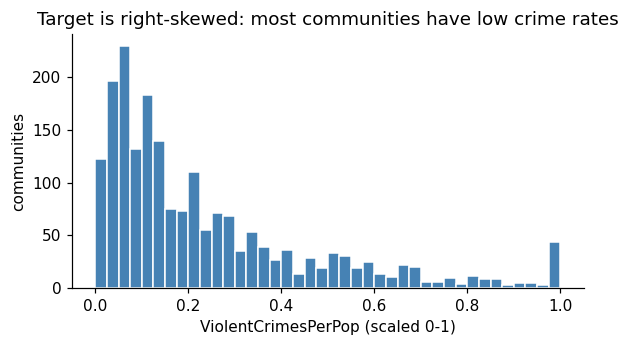

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(y, bins=40, color="steelblue", edgecolor="white")
ax.set_xlabel("ViolentCrimesPerPop (scaled 0-1)"); ax.set_ylabel("communities")
ax.set_title("Target is right-skewed: most communities have low crime rates")
plt.show()

### How redundant are the predictors?

Many columns measure nearly the same thing (e.g. `PctFam2Par`, `PctKids2Par`, `PctYoungKids2Par` — percent of two-parent households measured three ways; or income measured as median, per-capita, by race …).

pairs of predictors with |corr| > 0.9 : 49
pairs of predictors with |corr| > 0.8 : 126


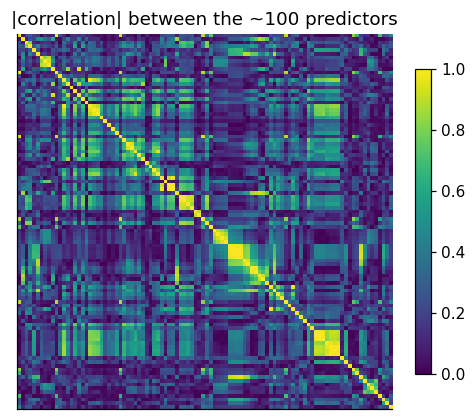

In [4]:
R = X.corr().abs().values
pairs = R[np.triu_indices_from(R, k=1)]
print(f"pairs of predictors with |corr| > 0.9 : {(pairs > 0.9).sum()}")
print(f"pairs of predictors with |corr| > 0.8 : {(pairs > 0.8).sum()}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(R, cmap="viridis", vmin=0, vmax=1)
ax.set_title("|correlation| between the ~100 predictors"); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 2. Train / test split and standardization

LASSO penalizes $|\beta_j|$, so every predictor must be on the same scale → standardize (fit the scaler on the **training** set only).

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)

scaler = StandardScaler().fit(X_tr)
Z_tr = scaler.transform(X_tr)
Z_te = scaler.transform(X_te)
names = X.columns.to_numpy()

print("train:", Z_tr.shape, "  test:", Z_te.shape)
print("condition number of training design:", f"{np.linalg.cond(Z_tr):.0f}")

train: (1494, 100)   test: (499, 100)
condition number of training design: 197


### OLS: uses *all* ~100 predictors

With strong collinearity the OLS coefficients are unstable: correlated predictors get large coefficients of **opposite sign** that nearly cancel.

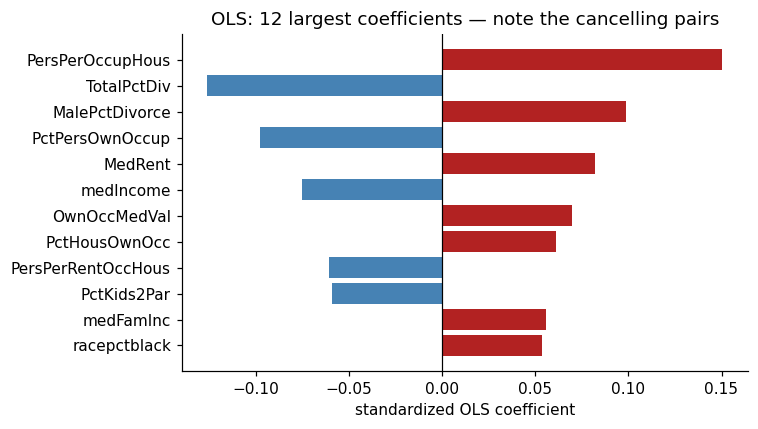

In [6]:
ols = LinearRegression().fit(Z_tr, y_tr)

top = np.argsort(-np.abs(ols.coef_))[:12]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(names[top][::-1], ols.coef_[top][::-1], color=np.where(ols.coef_[top][::-1] > 0, "firebrick", "steelblue"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("standardized OLS coefficient")
ax.set_title("OLS: 12 largest coefficients — note the cancelling pairs")
plt.tight_layout(); plt.show()

## 3. LASSO

$$
\hat\beta_\lambda=\arg\min_{\beta}\;\frac{1}{2n}\sum_{i=1}^n\big(y_i-\beta_0-x_i^\top\beta\big)^2\;+\;\lambda\sum_{j=1}^p|\beta_j|
$$

* $\lambda = 0$ → OLS.  $\lambda$ large → all $\beta_j = 0$.
* The $L_1$ penalty sets coefficients **exactly to zero** → automatic variable selection.
* (`scikit-learn` calls $\lambda$ `alpha`.)

### The regularization path
Fit LASSO for a whole grid of $\lambda$ values and track every coefficient.

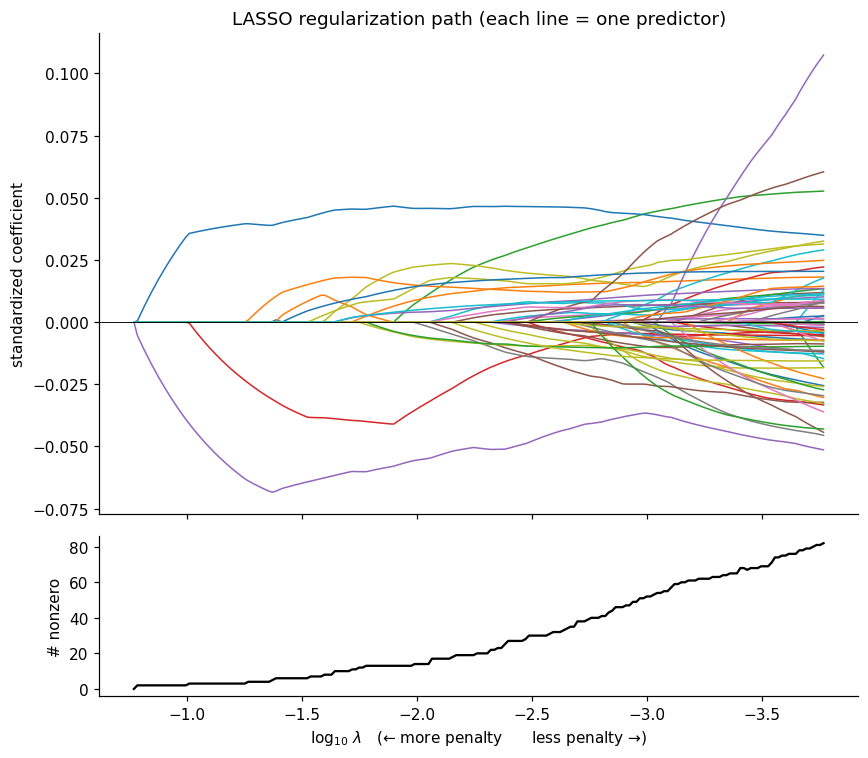

In [7]:
alphas, coefs, _ = lasso_path(Z_tr, y_tr - y_tr.mean(), n_alphas=200, eps=1e-3, max_iter=50_000)
n_active = (np.abs(coefs) > 0).sum(axis=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(np.log10(alphas), coefs.T, lw=1)
ax1.axhline(0, color="k", lw=0.6)
ax1.set_ylabel("standardized coefficient")
ax1.set_title("LASSO regularization path (each line = one predictor)")

ax2.plot(np.log10(alphas), n_active, color="k")
ax2.set_xlabel(r"$\log_{10}\,\lambda$   (← more penalty      less penalty →)")
ax2.set_ylabel("# nonzero")
ax1.invert_xaxis()
plt.tight_layout(); plt.show()

**Read the path from right to left:** at large $\lambda$ nothing is in the model; as $\lambda$ shrinks, predictors enter one by one. The *first* few to enter are the strongest (marginal) signals. At the far left we approach OLS with all predictors and wild coefficients.

**Question:** which $\lambda$ should we pick?

## 4. Choosing $\lambda$ with AIC and BIC

For a Gaussian linear model, LASSO's **effective degrees of freedom** ≈ number of nonzero coefficients $k_\lambda$ (Zou, Hastie & Tibshirani 2007). So we can use the classical criteria:

$$
\text{AIC}(\lambda)= n\log\hat\sigma^2_\lambda + 2\,k_\lambda,
\qquad
\text{BIC}(\lambda)= n\log\hat\sigma^2_\lambda + \log(n)\,k_\lambda
$$

* first term: fit (smaller RSS is better)
* second term: complexity penalty — **BIC's is larger** ($\log n \approx 7.3 > 2$) → BIC picks **sparser** models.
* Both need only *one* fit on the training data — no cross-validation.

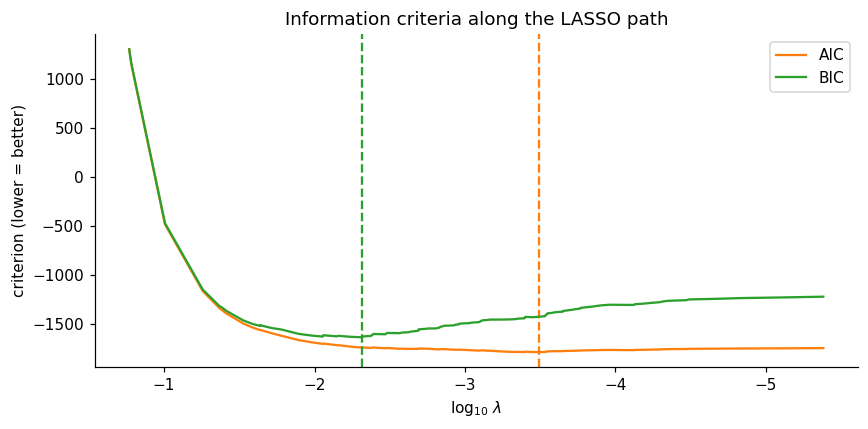

AIC: lambda = 0.00032   nonzero coefficients = 68
BIC: lambda = 0.00485   nonzero coefficients = 20


In [8]:
aic = LassoLarsIC(criterion="aic").fit(Z_tr, y_tr)
bic = LassoLarsIC(criterion="bic").fit(Z_tr, y_tr)

fig, ax = plt.subplots(figsize=(8, 4))
for m, c, lab in [(aic, "tab:orange", "AIC"), (bic, "tab:green", "BIC")]:
    ax.plot(np.log10(m.alphas_[:-1]), m.criterion_[:-1], color=c, label=lab)
    ax.axvline(np.log10(m.alpha_), color=c, ls="--")
ax.invert_xaxis()
ax.set_xlabel(r"$\log_{10}\,\lambda$"); ax.set_ylabel("criterion (lower = better)")
ax.set_title("Information criteria along the LASSO path"); ax.legend()
plt.tight_layout(); plt.show()

for lab, m in [("AIC", aic), ("BIC", bic)]:
    print(f"{lab}: lambda = {m.alpha_:.5f}   nonzero coefficients = {(m.coef_ != 0).sum()}")

### Comparison: 5-fold cross-validation

CV : lambda = 0.00042   nonzero coefficients = 65


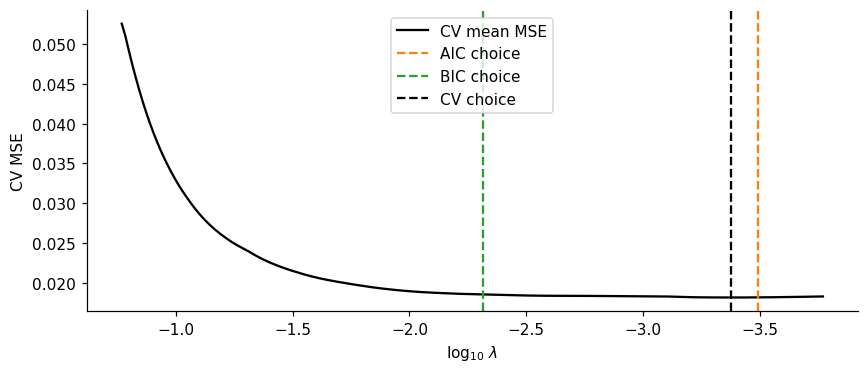

In [9]:
cv = LassoCV(cv=5, n_alphas=200, random_state=0).fit(Z_tr, y_tr)
print(f"CV : lambda = {cv.alpha_:.5f}   nonzero coefficients = {(cv.coef_ != 0).sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.log10(cv.alphas_), cv.mse_path_.mean(axis=1), color="k", label="CV mean MSE")
for m, c, lab in [(aic, "tab:orange", "AIC"), (bic, "tab:green", "BIC"), (cv, "k", "CV")]:
    ax.axvline(np.log10(m.alpha_), color=c, ls="--", label=f"{lab} choice")
ax.invert_xaxis(); ax.set_xlabel(r"$\log_{10}\,\lambda$"); ax.set_ylabel("CV MSE")
ax.legend(); plt.tight_layout(); plt.show()

### Put the chosen $\lambda$'s on the path

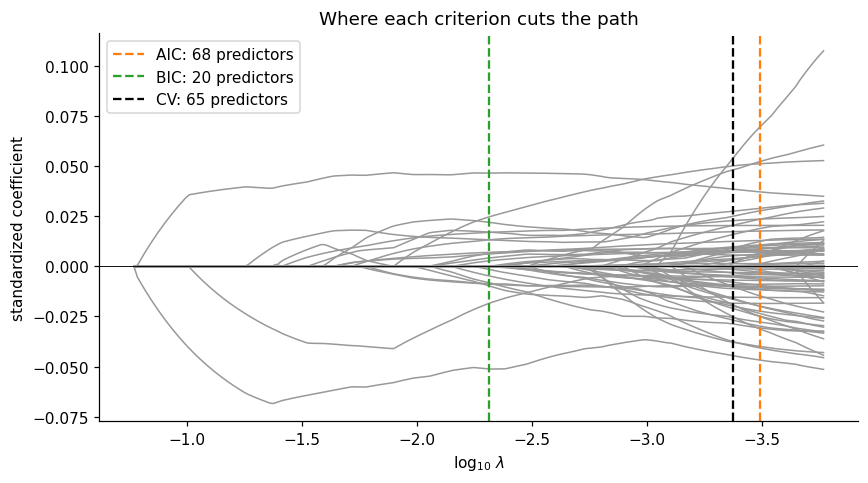

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.log10(alphas), coefs.T, lw=1, color="0.6")
for m, c, lab in [(aic, "tab:orange", "AIC"), (bic, "tab:green", "BIC"), (cv, "k", "CV")]:
    ax.axvline(np.log10(m.alpha_), color=c, ls="--", lw=1.5, label=f"{lab}: {(m.coef_ != 0).sum()} predictors")
ax.axhline(0, color="k", lw=0.6); ax.invert_xaxis()
ax.set_xlabel(r"$\log_{10}\,\lambda$"); ax.set_ylabel("standardized coefficient")
ax.set_title("Where each criterion cuts the path"); ax.legend()
plt.tight_layout(); plt.show()

### The BIC model: which predictors survived?

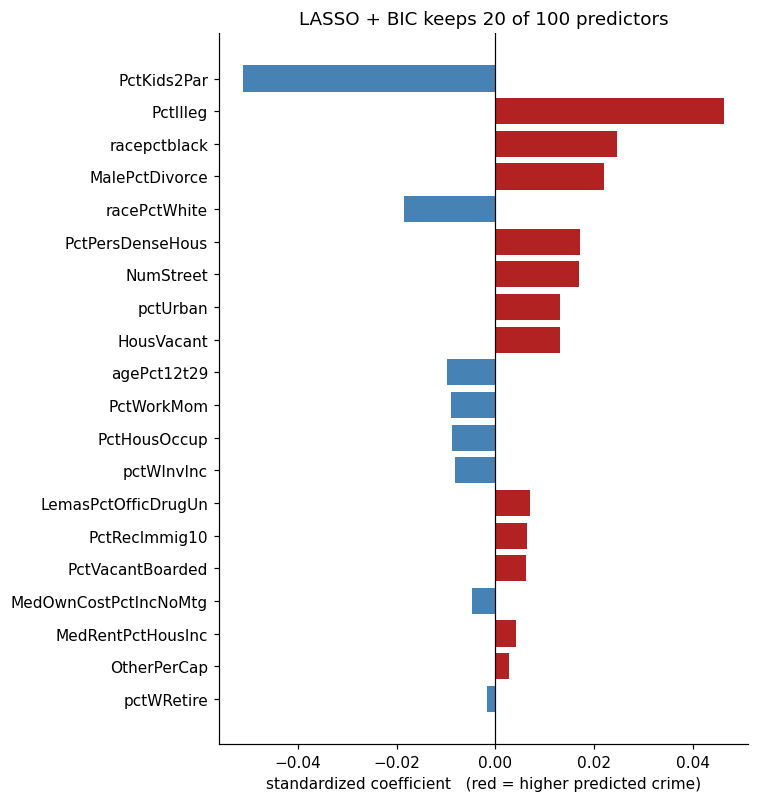

In [11]:
sel = np.flatnonzero(bic.coef_)
sel = sel[np.argsort(np.abs(bic.coef_[sel]))]

fig, ax = plt.subplots(figsize=(7, 0.32 * len(sel) + 1))
ax.barh(names[sel], bic.coef_[sel], color=np.where(bic.coef_[sel] > 0, "firebrick", "steelblue"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("standardized coefficient   (red = higher predicted crime)")
ax.set_title(f"LASSO + BIC keeps {len(sel)} of {len(names)} predictors")
plt.tight_layout(); plt.show()

Look up variable meanings in `communities.names` (e.g. `PctIlleg` = % of kids born to never-married parents, `PctKids2Par` = % kids in two-parent households, `racepctblack` = % of population African American, `HousVacant` = number of vacant households, …).

## 5. Test-set comparison

In [12]:
models = {"OLS (all)": ols, "LASSO-AIC": aic, "LASSO-BIC": bic, "LASSO-CV": cv}
rows = []
for name, m in models.items():
    pred = m.predict(Z_te)
    rows.append({"model": name,
                 "# predictors": int((m.coef_ != 0).sum()),
                 "test MSE": mean_squared_error(y_te, pred),
                 "test R²": r2_score(y_te, pred)})
pd.DataFrame(rows).set_index("model").round(4)

,# predictors,test MSE,test R²
model,,,
OLS (all),100,0.0195,0.6654
LASSO-AIC,68,0.0194,0.6668
LASSO-BIC,20,0.0200,0.6558
LASSO-CV,65,0.0194,0.6658


**Takeaway:** LASSO matches (or beats) OLS on new data while using a fraction of the predictors. BIC gives the most compact model at almost no cost in accuracy.

## 6. How stable is the selection?

Refit LASSO-BIC on 100 **bootstrap** resamples of the training data and record how often each predictor is selected.

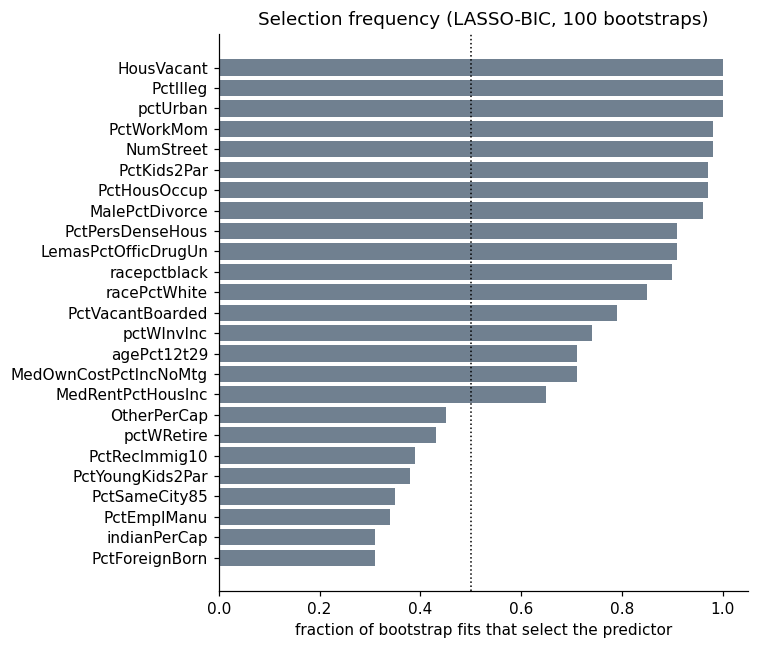

In [13]:
B = 100
picked = np.zeros(len(names))
n = len(y_tr)
for b in range(B):
    idx = rng.integers(0, n, n)
    m = LassoLarsIC(criterion="bic").fit(Z_tr[idx], y_tr.to_numpy()[idx])
    picked += (m.coef_ != 0)
freq = picked / B

order = np.argsort(-freq)[:25][::-1]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(names[order], freq[order], color="slategray")
ax.axvline(0.5, color="k", ls=":", lw=1)
ax.set_xlabel("fraction of bootstrap fits that select the predictor")
ax.set_title("Selection frequency (LASSO-BIC, 100 bootstraps)")
plt.tight_layout(); plt.show()

A few predictors are selected almost every time; many others come and go. When two predictors are highly correlated, LASSO tends to pick **one of them somewhat arbitrarily** — a different resample can pick the other.

## 7. Discussion: prediction ≠ explanation

* LASSO finds a **small set of predictors that predict well**. It does **not** find causes.
* A selected variable may be a **proxy**: race and family-structure variables correlate with income, segregation, housing policy, policing intensity and historical disinvestment. LASSO keeps whichever correlated column predicts best and drops the rest — the "dropped" variables are not unimportant.
* The target itself is *reported* crime (FBI UCR), which depends on policing and reporting practices.
* The police-funding variables were missing for 84% of communities and had to be dropped — what is *not* measured can't be selected.
* Using such a model to allocate police or resources can **feed back** into the data it was trained on.

**Questions for students**
1. If the race columns were removed from the data, what would LASSO select instead? Try it below.
2. Why does BIC choose fewer variables than AIC? When would you prefer each?
3. Is a predictor with bootstrap selection frequency 0.3 "unimportant"?

In [14]:
# Exercise 1: remove some columns, refit LASSO-BIC, and see what replaces them
def refit_without(drop):
    keep = [c for c in X.columns if c not in drop]
    sc = StandardScaler().fit(X_tr[keep])
    m = LassoLarsIC(criterion="bic").fit(sc.transform(X_tr[keep]), y_tr)
    after = set(np.array(keep)[m.coef_ != 0])
    before = set(names[bic.coef_ != 0])
    print("dropped           :", drop)
    print("newly selected    :", sorted(after - before))
    print(f"test R²           : {r2_score(y_te, m.predict(sc.transform(X_te[keep]))):.4f}"
          f"   (was {r2_score(y_te, bic.predict(Z_te)):.4f})\n")

refit_without(["racepctblack", "racePctWhite"])
refit_without(["PctKids2Par"])

dropped           : ['racepctblack', 'racePctWhite']
newly selected    : ['HispPerCap', 'MedRent', 'PctEmplManu', 'PctImmigRec10', 'racePctAsian', 'whitePerCap']
test R²           : 0.6462   (was 0.6558)

dropped           : ['PctKids2Par']
newly selected    : ['PctFam2Par', 'pctWWage']
test R²           : 0.6471   (was 0.6558)



Removing the race columns barely changes accuracy: LASSO substitutes **other columns that carry the same information** (race-specific per-capita income, immigration, rent …). Dropping a sensitive variable does not remove the information — this is the proxy problem in algorithmic fairness.